<a href="https://colab.research.google.com/github/DhimanTarafdar/dengue-virus-research/blob/main/dengue_virus_research_part1_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dengue Part 1: genomic and evolutionary analysis of DENV-1/2/3 in Bangladesh (2000-2025)

Run the cells from top to bottom. Main steps:

1. Load the Bangladeshi sequences and check serotype labels
2. Quality control (template sequences, ambiguous bases, duplicates)
3. Extract the E gene and download global background data (Nextstrain)
4. Genotype assignment
5. Alignment and maximum-likelihood trees (IQ-TREE, UFBoot + SH-aLRT)
6. Serotype and genotype dominance over time
7. Temporal signal and dated trees (TreeTime)
8. Recombination check (GARD) and selection analysis on the E gene (HyPhy FEL, SLAC, FUBAR)

Upload `DENGU-VIRUS-CSV.csv` and `DENGUE-VIRUS-sequences.fasta` to `/content` before starting.

## 0. Setup

In [ ]:
!pip install -q biopython mappy zstandard phylo-treetime
!apt-get -qq install -y mafft iqtree > /dev/null

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


HyPhy has to be built from source. This takes a while, so run it once.

In [ ]:
!apt-get -qq install -y cmake libcurl4-openssl-dev > /dev/null
!git clone -q --depth 1 https://github.com/veg/hyphy.git /content/hyphy
%cd /content/hyphy
!cmake . > /dev/null
!make -j2 hyphy > /dev/null 2>&1
!make install > /dev/null 2>&1
%cd /content
!which hyphy

/content/hyphy
/content
/usr/local/bin/hyphy


In [ ]:
import os, re, io, json, shutil, random, subprocess, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mappy as mp
import zstandard
from Bio import SeqIO, Phylo
from Bio.Seq import Seq

CSV_PATH = "/kaggle/input/datasets/dhimantarafdar/bd-dengue-data/DENGU-VIRUS-CSV.csv"
FASTA_PATH = "/kaggle/input/datasets/dhimantarafdar/bd-dengue-data/DENGUE-VIRUS-sequences.fasta"
OUT = "/kaggle/working/part1_outputt"

SEROTYPES = ["DENV-1", "DENV-2", "DENV-3"]
NS_NAME = {"DENV-1": "denv1", "DENV-2": "denv2", "DENV-3": "denv3"}
REFSEQ = {"DENV-1": "NC_001477", "DENV-2": "NC_001474", "DENV-3": "NC_001475"}
E_LENGTH = {"DENV-1": 1485, "DENV-2": 1485, "DENV-3": 1479}

MIN_E_LEN = 1400        # shorter E sequences are treated as partial
MAX_E_N = 0.01          # max fraction of non-ACGT bases in the E gene
MIN_GENOME_LEN = 10000  # complete (or nearly complete) genomes
MIN_GENOMES = 15        # minimum Bangladeshi genomes needed for a genome-level analysis
N_CLOSE = 3             # closest global relatives kept for every Bangladeshi E sequence
MAX_BACKBONE = 100      # backbone sequences per serotype (one per lineage and 5-year bin)
N_DRT = 20              # date-randomisation replicates (use 100 for the final run)
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
for folder in ["tables", "figures", "global", "work", "trees", "hyphy"]:
    os.makedirs(f"{OUT}/{folder}", exist_ok=True)

def run(cmd, log=None):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True, stdin=subprocess.DEVNULL)
    if log:
        open(log, "w").write(r.stdout + r.stderr)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        raise RuntimeError("command failed: " + cmd)
    return r.stdout

def save_fig(name):
    plt.savefig(f"{OUT}/figures/{name}.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT}/figures/{name}.pdf", bbox_inches="tight")

## 1. Bangladeshi sequences

In [ ]:
df = pd.read_csv(CSV_PATH)
seqs = {}
for rec in SeqIO.parse(FASTA_PATH, "fasta"):
    seqs[rec.id.split(".")[0]] = str(rec.seq).upper()

assert set(df["Accession"]) == set(seqs), "CSV and FASTA accessions do not match"
df["seq"] = df["Accession"].map(seqs)
print(df.shape, "| length mismatch with CSV:", (df["seq"].str.len() != df["Length"]).sum())

# serotype written in the NCBI organism name
def label_to_serotype(name):
    last = str(name).lower().split()[-1]
    codes = {"1": "DENV-1", "i": "DENV-1", "2": "DENV-2", "ii": "DENV-2",
             "3": "DENV-3", "iii": "DENV-3", "4": "DENV-4", "iv": "DENV-4"}
    return codes.get(last, "Unknown")

df["ncbi_serotype"] = df["Organism_Name"].apply(label_to_serotype)

# collection date -> year and an ISO date (XX = unknown part, TreeTime understands this)
def parse_date(s):
    m = re.match(r"(\d{4})(?:-(\d{2}))?(?:-(\d{2}))?", str(s))
    if not m:
        return np.nan, None
    y, mo, d = m.groups()
    return int(y), f"{y}-{mo or 'XX'}-{d or 'XX'}"

parsed = df["Collection_Date"].apply(parse_date)
df["year"] = [p[0] for p in parsed]
df["date_iso"] = [p[1] for p in parsed]

# some sequences have no date, but the isolate name contains BDH02 (2002); please verify this
mask = df["Isolate"].astype(str).str.contains("BDH02") & df["year"].isna()
df.loc[mask, "year"] = 2002
df.loc[mask, "date_iso"] = "2002-XX-XX"
print("year taken from isolate name:", mask.sum(), "| still without year:", df["year"].isna().sum())

# fraction of non-ACGT bases
df["n_frac"] = df["seq"].apply(lambda s: 1 - sum(s.count(b) for b in "ACGT") / len(s))

(664, 16) | length mismatch with CSV: 0
year taken from isolate name: 8 | still without year: 6


## 2. Global background data (Nextstrain)

In [ ]:
base_url = "https://data.nextstrain.org/files/workflows/dengue"

def download_zst(url, path):
    if os.path.exists(path):
        return
    with urllib.request.urlopen(url) as r, open(path, "wb") as f:
        zstandard.ZstdDecompressor().copy_stream(r, f)

meta_g, glob_seq = {}, {}
for s in NS_NAME.values():
    mpath = f"{OUT}/global/metadata_{s}.tsv"
    spath = f"{OUT}/global/sequences_{s}.fasta"
    download_zst(f"{base_url}/metadata_{s}.tsv.zst", mpath)
    download_zst(f"{base_url}/sequences_{s}.fasta.zst", spath)
    meta_g[s] = pd.read_csv(mpath, sep="\t", low_memory=False).assign(file=s)
    glob_seq[s] = {r.id: str(r.seq).upper() for r in SeqIO.parse(spath, "fasta")}
    print(s, "metadata:", len(meta_g[s]), "| sequences:", len(glob_seq[s]))

meta_all = pd.concat(meta_g.values()).drop_duplicates("accession")

denv1 metadata: 22109 | sequences: 22109
denv2 metadata: 20446 | sequences: 20446
denv3 metadata: 10027 | sequences: 10027


## 3. Serotype check and quality control

NCBI labels are not always correct, so every sequence is compared with the RefSeq genome of each serotype (shared 10-mers).

In [ ]:
def kmers(s, k=10):
    return {s[i:i + k] for i in range(len(s) - k + 1)}

for s in SEROTYPES:
    assert REFSEQ[s] in glob_seq[NS_NAME[s]], f"{REFSEQ[s]} not found in the Nextstrain data"
ref_kmers = {s: kmers(glob_seq[NS_NAME[s]][REFSEQ[s]]) for s in SEROTYPES}

rows = []
for acc, seq in seqs.items():
    k = kmers(seq)
    score = {s: len(k & ref_kmers[s]) / max(len(k), 1) for s in SEROTYPES}
    best = max(score, key=score.get)
    top = sorted(score.values(), reverse=True)
    rows.append([acc, best, top[0], top[0] - top[1]])
ks = pd.DataFrame(rows, columns=["Accession", "kmer_sero", "kmer_score", "kmer_margin"])
df = df.merge(ks, on="Accession")

# use the sequence-based serotype only when the match is clear, otherwise keep the NCBI label
clear = (df["kmer_score"] >= 0.10) & (df["kmer_margin"] >= 0.05)
df["serotype"] = np.where(clear, df["kmer_sero"], df["ncbi_serotype"])
df["label_wrong"] = clear & (df["kmer_sero"] != df["ncbi_serotype"])

print(pd.crosstab(df["ncbi_serotype"], df["serotype"], margins=True))
df[df["label_wrong"]].drop(columns="seq").to_csv(f"{OUT}/tables/wrong_serotype_labels.csv", index=False)

# who submitted the wrongly labelled records, when, and how long are they
wrong = df[df["label_wrong"]]
print("\nwrongly labelled records:", len(wrong))
print(pd.crosstab(wrong["ncbi_serotype"], wrong["serotype"]))
print("collection years:", wrong["year"].value_counts().sort_index().to_dict())
print("length (min / median / max):", wrong["Length"].min(), "/", wrong["Length"].median(), "/", wrong["Length"].max())
for c in [c for c in df.columns if re.search(r"submit|study|author|center|bioproject", c, re.I)]:
    print(c, wrong[c].value_counts().head(5).to_dict())

serotype       DENV-1  DENV-2  DENV-3  DENV-4  All
ncbi_serotype                                     
DENV-1             29       0      44       0   73
DENV-2              0     278       0       0  278
DENV-3              0       0     310       0  310
DENV-4              0       0       0       3    3
All                29     278     354       3  664

wrongly labelled records: 44
serotype       DENV-3
ncbi_serotype        
DENV-1             44
collection years: {2020.0: 1, 2021.0: 43}
length (min / median / max): 395 / 5913.5 / 10669
Submitters {'Jahan,A., Shyamal,K., Aung,M.S., Kobayashi,N.': 22, 'Sarkar,M.M., Islam,M.S., Miah,M.I., Akter,S., Banu,T.A., Goswami,B., Jahan,I., Habib,M.A., Shaikh,M.A., Rubaiya,A., Ilias,M., Khan,M.S.': 17, 'Rahman,M.S., Sarker,M.M.H., Khan,S.': 2, 'Sarkar,M.M., Rabbi,M.F., Akter,S., Islam,M.S., Banu,T.A., Jahan,I., Miah,M.I., Goswami,B., Habib,M.A., Akhteruzzaman,S., Shaikh,M.A., Rubaiya,A., Ilias,M., Khan,M.S.': 1, 'Rahman,M., Sarker,M.M.H., Khan,S

In [ ]:
# complete genomes that are identical to many other sequences are probably template sequences
df["same_count"] = df.groupby("seq")["Accession"].transform("size")
df["suspect_template"] = (df["Length"] > 9000) & (df["same_count"] >= 10)

# complete genomes that are almost identical to the RefSeq genome (not a real recent isolate)
df["suspect_ref"] = (df["Length"] > 9000) & (df["kmer_score"] >= 0.95)

print("suspect template sequences:", df["suspect_template"].sum())
print("suspect RefSeq-like genomes:", df["suspect_ref"].sum())
df[df["suspect_template"] | df["suspect_ref"]].drop(columns="seq").to_csv(f"{OUT}/tables/suspect_sequences.csv", index=False)

suspect template sequences: 18
suspect RefSeq-like genomes: 19


## 4. E gene extraction

In [ ]:
# E reference for each serotype: an exact-length E sequence without ambiguous bases and without stop codons
e_ref = {}
for s in SEROTYPES:
    pool = df[(df["serotype"] == s) & (df["Length"] == E_LENGTH[s]) & (df["n_frac"] == 0)]
    for acc in pool["Accession"]:
        if "*" not in str(Seq(seqs[acc]).translate()):
            e_ref[s] = acc
            break
    assert s in e_ref, f"no E reference found for {s}"

# check that the E reference really sits at the E gene position of the RefSeq genome
for s in SEROTYPES:
    aligner = mp.Aligner(seq=glob_seq[NS_NAME[s]][REFSEQ[s]], preset="map-ont")
    hit = max(aligner.map(seqs[e_ref[s]]), key=lambda h: h.mlen)
    print(s, e_ref[s], "maps to RefSeq position", hit.r_st, "-", hit.r_en)
    assert 900 <= hit.r_st <= 1000, "E reference is not at the E gene position, choose it manually"

e_aligner = {s: mp.Aligner(seq=seqs[e_ref[s]], preset="map-ont") for s in SEROTYPES}

def get_E(seq, sero):
    hits = [h for h in e_aligner[sero].map(seq) if h.strand == 1]
    if not hits:
        return None
    best = max(hits, key=lambda h: h.mlen)
    return seq[best.q_st:best.q_en]

def n_fraction(s):
    return 1 - sum(s.count(b) for b in "ACGT") / len(s)

e_seq = {}
for acc, sero, length in zip(df["Accession"], df["serotype"], df["Length"]):
    if sero in SEROTYPES and length >= MIN_E_LEN:
        e = get_E(seqs[acc], sero)
        if e:
            e_seq[acc] = e

df["E_seq"] = df["Accession"].map(e_seq)
df["E_len"] = df["E_seq"].str.len()
df["E_n_frac"] = df["E_seq"].apply(lambda s: n_fraction(s) if isinstance(s, str) else np.nan)
df["E_ok"] = (df["E_len"] >= MIN_E_LEN) & (df["E_n_frac"] <= MAX_E_N)

def region(r):
    if r["Length"] >= MIN_GENOME_LEN:
        return "complete genome"
    if r["E_len"] >= MIN_E_LEN:
        return "E gene"
    return "other region / partial"

df["region"] = df.apply(region, axis=1)
print(pd.crosstab(df["serotype"], df["region"]))
print(df["E_len"].value_counts().head(6))

# final flag: sequences used for the E gene analyses
df["use_E"] = df["E_ok"] & df["serotype"].isin(SEROTYPES) & ~df["suspect_template"] & ~df["suspect_ref"]
print("sequences used for E gene analyses:", df["use_E"].sum())

# most common E length per serotype (sequences of this length are compared position by position)
E_MODAL = df[df["use_E"]].groupby("serotype")["E_len"].agg(lambda x: int(x.mode()[0])).to_dict()
print("most common E length:", E_MODAL)

DENV-1 OQ826841 maps to RefSeq position 934 - 2419
DENV-2 PZ017579 maps to RefSeq position 936 - 2421
DENV-3 PZ017435 maps to RefSeq position 934 - 2413
region    E gene  complete genome  other region / partial
serotype                                                 
DENV-1        15                7                       7
DENV-2       120               24                     134
DENV-3       203               69                      82
DENV-4         0                2                       1
E_len
1479.0    262
1485.0    144
1484.0     19
1478.0      7
1406.0      2
1442.0      2
Name: count, dtype: int64
sequences used for E gene analyses: 411
most common E length: {'DENV-1': 1485, 'DENV-2': 1485, 'DENV-3': 1479}


Global E sequences: only non-Bangladeshi sequences with full E coverage are used.

In [ ]:
bd_acc = set(df["Accession"])
mg = meta_all[(meta_all["country"] != "Bangladesh") & (meta_all["E_coverage"] >= 0.99) & ~meta_all["accession"].isin(bd_acc)]

rows = []
for sero in SEROTYPES:
    sub = mg[mg["file"] == NS_NAME[sero]]
    for r in sub.itertuples():
        seq = glob_seq[NS_NAME[sero]].get(r.accession)
        if seq is None or len(seq) < MIN_E_LEN:
            continue
        e = get_E(seq, sero)
        if e and len(e) >= MIN_E_LEN and n_fraction(e) <= MAX_E_N:
            year, date_iso = parse_date(r.date)
            rows.append(dict(accession=r.accession, serotype=sero, E_seq=e, country=r.country, year=year,
                             date_iso=date_iso, genotype=r.genotype, major=r.major_lineage, minor=r.minor_lineage,
                             has_genome=len(seq) >= MIN_GENOME_LEN))
gE = pd.DataFrame(rows)
print(gE.groupby("serotype").size())

serotype
DENV-1    18665
DENV-2    14937
DENV-3     6050
dtype: int64


## 5. Genotype assignment

Genotype and lineage come from the Nextstrain labels. Sequences without a label get the genotype of their closest global E sequence. The two methods are compared where both exist.

In [ ]:
CODE = np.full(256, 4, dtype=np.uint8)
for i, b in enumerate("ACGT"):
    CODE[ord(b)] = i

def encode(s):
    return CODE[np.frombuffer(s.encode(), dtype=np.uint8)]

def nearest(queries, pool, k):
    # number of differences between every query and every pool sequence (same length, N ignored)
    P = np.array([encode(s) for s in pool])
    result = []
    for q in queries:
        qa = encode(q)
        d = ((P != qa) & (P < 4) & (qa < 4)).sum(axis=1)
        idx = np.argsort(d, kind="stable")[:k]
        result.append((idx, d[idx]))
    return result

ns = meta_all[["accession", "genotype", "major_lineage", "minor_lineage"]].rename(
    columns={"accession": "Accession", "genotype": "ns_genotype", "major_lineage": "ns_major", "minor_lineage": "ns_minor"})
df = df.merge(ns, on="Accession", how="left")

close = {}      # serotype -> indices (in gE) of the closest global relatives
nn_rows = []
for s in SEROTYPES:
    q = df[df["use_E"] & (df["serotype"] == s) & (df["E_len"] == E_MODAL[s])].drop_duplicates("E_seq")
    pool = gE[(gE["serotype"] == s) & (gE["E_seq"].str.len() == E_MODAL[s]) & gE["genotype"].notna()]
    res = nearest(q["E_seq"].tolist(), pool["E_seq"].tolist(), N_CLOSE)
    close[s] = set()
    for e, (idx, dist) in zip(q["E_seq"], res):
        near = pool.iloc[idx[0]]
        nn_rows.append(dict(E_seq=e, nn_acc=near["accession"], nn_country=near["country"], nn_year=near["year"],
                            nn_genotype=near["genotype"], nn_dist=int(dist[0])))
        close[s].update(pool.index[idx])

nn = pd.DataFrame(nn_rows)
df = df.merge(nn, on="E_seq", how="left")
df["genotype"] = df["ns_genotype"].fillna(df["nn_genotype"])
df["genotype_source"] = np.where(df["ns_genotype"].notna(), "Nextstrain", np.where(df["nn_genotype"].notna(), "closest relative", "none"))
df["genotype"] = df["genotype"].fillna("Unassigned")

both = df[df["ns_genotype"].notna() & df["nn_genotype"].notna()]
print("agreement between Nextstrain label and closest-relative genotype:", round((both["ns_genotype"] == both["nn_genotype"]).mean(), 3), f"(n={len(both)})")
print(pd.crosstab(df[df["use_E"]]["serotype"], df[df["use_E"]]["genotype"]))

agreement between Nextstrain label and closest-relative genotype: 1.0 (n=381)
genotype  1I  1III  2II   3I  3II
serotype                         
DENV-1     3    17    0    0    0
DENV-2     0     0  143    0    0
DENV-3     0     0    0  210   38


In [ ]:
# optional: cross-check with the Genome Detective Dengue Typing Tool (upload its csv result to this path)
GD_FILE = "/content/genome_detective.csv"
if os.path.exists(GD_FILE):
    gd = pd.read_csv(GD_FILE)
    id_col = next(c for c in gd.columns if re.search(r"name|sequence|id|accession", c, re.I))
    gt_col = next(c for c in gd.columns if re.search(r"genotype", c, re.I))
    gd["Accession"] = gd[id_col].astype(str).str.extract(r"([A-Z]{1,2}_?\d{5,8})")[0]
    gd = gd.drop_duplicates("Accession").rename(columns={gt_col: "genotype_gd"})[["Accession", "genotype_gd"]]
    df = df.merge(gd, on="Accession", how="left")
    print(pd.crosstab(df["genotype"], df["genotype_gd"].fillna("none")))
else:
    print("no Genome Detective file found, skipping")

no Genome Detective file found, skipping


## 6. Sample overview

                           step   n
      All Bangladeshi sequences 664
 DENV-1/2/3 (sequence-verified) 661
         With E gene >= 1400 bp 437
E gene with few ambiguous bases 430
    Not template or RefSeq-like 411
           With collection year 405


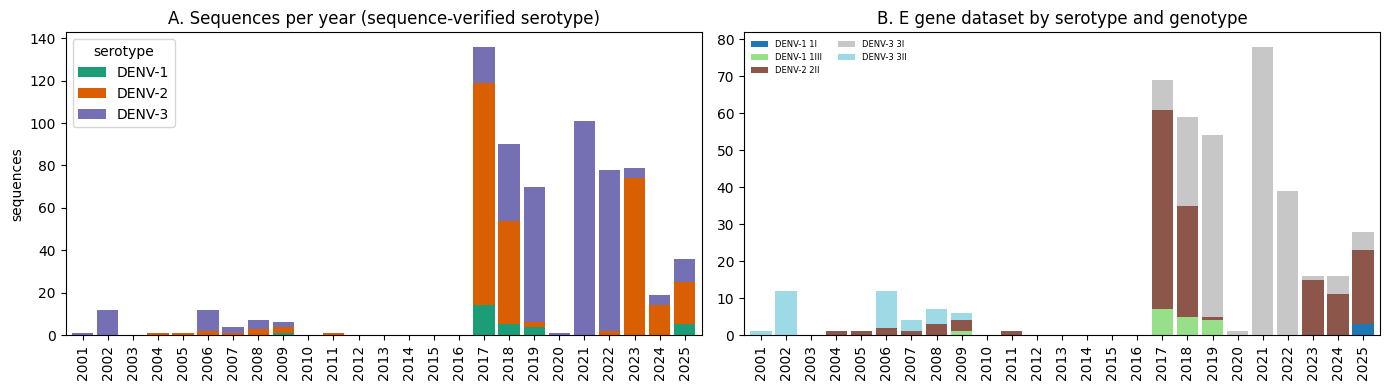

In [ ]:
flow = pd.DataFrame({
    "step": ["All Bangladeshi sequences", "DENV-1/2/3 (sequence-verified)", "With E gene >= " + str(MIN_E_LEN) + " bp",
             "E gene with few ambiguous bases", "Not template or RefSeq-like", "With collection year"],
    "n": [len(df),
          df["serotype"].isin(SEROTYPES).sum(),
          (df["serotype"].isin(SEROTYPES) & (df["E_len"] >= MIN_E_LEN)).sum(),
          (df["serotype"].isin(SEROTYPES) & df["E_ok"]).sum(),
          df["use_E"].sum(),
          (df["use_E"] & df["year"].notna()).sum()]})
print(flow.to_string(index=False))
flow.to_csv(f"{OUT}/tables/sample_flow.csv", index=False)

d = df[df["serotype"].isin(SEROTYPES) & df["year"].notna()]
years = range(int(d["year"].min()), int(d["year"].max()) + 1)
tab_s = pd.crosstab(d["year"].astype(int), d["serotype"]).reindex(years, fill_value=0)
e = df[df["use_E"] & df["year"].notna()]
tab_g = pd.crosstab(e["year"].astype(int), e["serotype"] + " " + e["genotype"]).reindex(years, fill_value=0)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
tab_s.plot(kind="bar", stacked=True, ax=ax[0], width=0.85, color=["#1b9e77", "#d95f02", "#7570b3"])
ax[0].set_title("A. Sequences per year (sequence-verified serotype)")
ax[0].set_xlabel("")
ax[0].set_ylabel("sequences")
tab_g.plot(kind="bar", stacked=True, ax=ax[1], width=0.85, colormap="tab20")
ax[1].set_title("B. E gene dataset by serotype and genotype")
ax[1].set_xlabel("")
ax[1].legend(fontsize=6, ncol=2, frameon=False)
plt.tight_layout()
save_fig("Fig1_sequences_per_year")
plt.show()
tab_s.to_csv(f"{OUT}/tables/sequences_per_year.csv")

### Serotype and genotype dominance over time

Years with fewer than `MIN_PER_YEAR` sequences are not used to call the dominant type. GenBank sequences are not a random sample of cases, so "dominant" here means dominant among the sequenced samples.

serotype  DENV-1  DENV-2  DENV-3    n dominant
year                                          
2001         0.0     0.0   100.0    1  too few
2002         0.0     0.0   100.0   12   DENV-3
2004         0.0   100.0     0.0    1  too few
2005         0.0   100.0     0.0    1  too few
2006         0.0    16.7    83.3   12   DENV-3
2007         0.0    25.0    75.0    4  too few
2008         0.0    42.9    57.1    7   DENV-3
2009        16.7    50.0    33.3    6   DENV-2
2011         0.0   100.0     0.0    1  too few
2017        10.3    77.2    12.5  136   DENV-2
2018         5.6    54.4    40.0   90   DENV-2
2019         5.7     2.9    91.4   70   DENV-3
2020         0.0     0.0   100.0    1  too few
2021         0.0     0.0   100.0  101   DENV-3
2022         0.0     2.6    97.4   78   DENV-3
2023         0.0    93.7     6.3   79   DENV-2
2024         0.0    73.7    26.3   19   DENV-2
2025        13.9    55.6    30.6   36   DENV-2

Dominant serotype over time:
  DENV-3: 2002 to 2008
  DENV-

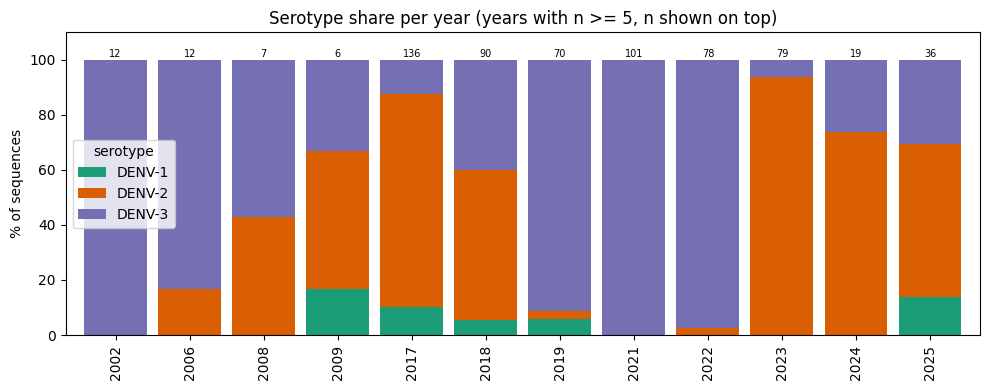

In [ ]:
from scipy.stats import chi2_contingency

MIN_PER_YEAR = 5

def dominance_order(dominant):
    # list of [type, first, last] in time order, consecutive years with the same type are merged
    order = []
    for key, lab in dominant.items():
        if lab == "too few":
            continue
        if order and order[-1][0] == lab:
            order[-1][2] = key
        else:
            order.append([lab, key, key])
    return order

def print_order(order):
    seen = set()
    for lab, a, b in order:
        again = "  <- dominant again (re-emergence, check sample size)" if lab in seen else ""
        print(f"  {lab}: {a} to {b}{again}")
        seen.add(lab)

d = df[df["serotype"].isin(SEROTYPES) & df["year"].notna()].copy()
d["year"] = d["year"].astype(int)
d["period"] = (d["year"] // 5 * 5).astype(str) + "-" + (d["year"] // 5 * 5 + 4).astype(str)

# serotype share per year
count = pd.crosstab(d["year"], d["serotype"]).reindex(columns=SEROTYPES, fill_value=0)
n_year = count.sum(axis=1)
share = (count.div(n_year, axis=0) * 100).round(1)
share["n"] = n_year
share["dominant"] = np.where(n_year >= MIN_PER_YEAR, count.idxmax(axis=1), "too few")
share.to_csv(f"{OUT}/tables/serotype_share_by_year.csv")
print(share.to_string())
print("\nDominant serotype over time:")
print_order(dominance_order(share["dominant"]))

# serotype share per 5-year period and a simple chi-square test (descriptive only, sampling is not random)
per = pd.crosstab(d["period"], d["serotype"]).reindex(columns=SEROTYPES, fill_value=0)
per_share = (per.div(per.sum(axis=1), axis=0) * 100).round(1).assign(n=per.sum(axis=1))
per_share.to_csv(f"{OUT}/tables/serotype_share_by_period.csv")
print("\n", per_share.to_string())
chi = chi2_contingency(per.loc[:, per.sum() > 0][per.sum(axis=1) > 0])
print("chi-square: serotype mix differs between periods, p =", f"{chi[1]:.2e}", "(df =", chi[2], ")")

# genotype turnover inside every serotype (5-year periods)
g = d[d["genotype"] != "Unassigned"]
gt_rows = []
for s in SEROTYPES:
    gs = g[g["serotype"] == s]
    if gs.empty:
        continue
    tab = pd.crosstab(gs["period"], gs["genotype"])
    dom = pd.Series(np.where(tab.sum(axis=1) >= MIN_PER_YEAR, tab.idxmax(axis=1), "too few"), index=tab.index)
    print(f"\n{s} genotypes per period (counts)")
    print(tab.assign(dominant=dom).to_string())
    print_order(dominance_order(dom))
    gt_rows.append(tab.assign(serotype=s, dominant=dom).reset_index())
pd.concat(gt_rows).to_csv(f"{OUT}/tables/genotype_by_period.csv", index=False)

# Fig 1b: serotype share per year (only years with enough sequences)
ok = share[share["n"] >= MIN_PER_YEAR]
fig, ax = plt.subplots(figsize=(10, 4))
ok[SEROTYPES].plot(kind="bar", stacked=True, ax=ax, width=0.85, color=["#1b9e77", "#d95f02", "#7570b3"])
for i, n in enumerate(ok["n"]):
    ax.text(i, 101, int(n), ha="center", fontsize=7)
ax.set_ylim(0, 110)
ax.set_ylabel("% of sequences")
ax.set_xlabel("")
ax.set_title(f"Serotype share per year (years with n >= {MIN_PER_YEAR}, n shown on top)")
plt.tight_layout()
save_fig("Fig1b_serotype_share")
plt.show()

## 7. Datasets for the trees

For every serotype the E dataset has the Bangladeshi sequences plus global background: the closest relatives of every Bangladeshi sequence and a backbone with one sequence per lineage and 5-year bin.
Identical sequences from the same year are kept only once. Genome-level datasets are built for serotypes with enough Bangladeshi complete genomes.

In [ ]:
def tip_name_bd(r):
    year = "NA" if pd.isna(r["year"]) else int(r["year"])
    return f"BD_{r['Accession']}_{year}"

def tip_name_global(r):
    country = re.sub(r"[^A-Za-z0-9]", "_", str(r["country"]))
    return f"{r['accession']}_{country}_{str(r['date_iso']).replace('-', '_')}"

def backbone(sub, group_col):
    sub = sub.copy()
    sub["bin"] = (sub["year"] // 5 * 5).fillna(0)
    pick = sub.groupby([group_col, "bin"]).sample(1, random_state=SEED)
    if len(pick) > MAX_BACKBONE:
        pick = pick.sample(MAX_BACKBONE, random_state=SEED)
    return pick

datasets = {}
for s in SEROTYPES:
    bd = df[df["use_E"] & (df["serotype"] == s)].drop_duplicates(["E_seq", "year"]).copy()
    bd["tip"] = bd.apply(tip_name_bd, axis=1)
    bd_part = pd.DataFrame({"tip": bd["tip"], "source": "Bangladesh", "year": bd["year"], "date_iso": bd["date_iso"],
                            "genotype": bd["genotype"], "seq": bd["E_seq"]})

    g = gE[gE["serotype"] == s]
    bg = pd.concat([g.loc[sorted(close[s])], backbone(g[g["genotype"].notna()], "major")]).drop_duplicates("accession")
    bg = bg.drop_duplicates(["E_seq", "year"]).copy()
    bg["tip"] = bg.apply(tip_name_global, axis=1)
    bg_part = pd.DataFrame({"tip": bg["tip"], "source": "Global", "year": bg["year"], "date_iso": bg["date_iso"],
                            "genotype": bg["genotype"], "seq": bg["E_seq"]})
    datasets[f"{s}_E"] = pd.concat([bd_part, bg_part], ignore_index=True)
    print(s, "E dataset:", len(bd_part), "Bangladesh +", len(bg_part), "global")

DENV-1 E dataset: 19 Bangladesh + 109 global
DENV-2 E dataset: 101 Bangladesh + 117 global
DENV-3 E dataset: 141 Bangladesh + 104 global


In [ ]:
# genome-level datasets (better temporal signal), only for serotypes with enough Bangladeshi genomes
for s in SEROTYPES:
    bd = df[(df["serotype"] == s) & (df["Length"] >= MIN_GENOME_LEN) & (df["n_frac"] <= 0.05)
            & ~df["suspect_template"] & ~df["suspect_ref"]].drop_duplicates(["seq", "year"]).copy()
    if len(bd) < MIN_GENOMES:
        print(s, "only", len(bd), "Bangladeshi genomes, no genome-level analysis")
        continue
    bd["tip"] = bd.apply(tip_name_bd, axis=1)
    bd_part = pd.DataFrame({"tip": bd["tip"], "source": "Bangladesh", "year": bd["year"], "date_iso": bd["date_iso"],
                            "genotype": bd["genotype"], "seq": bd["seq"]})
    bd_genotypes = set(bd["genotype"])

    # global genomes: closest relatives (by E gene) of the Bangladeshi genomes + lineage backbone
    g = gE[(gE["serotype"] == s) & gE["has_genome"] & gE["genotype"].isin(bd_genotypes)]
    pool = g[g["E_seq"].str.len() == E_MODAL[s]]
    q = bd[bd["E_len"] == E_MODAL[s]].drop_duplicates("E_seq")
    res = nearest(q["E_seq"].tolist(), pool["E_seq"].tolist(), 5)
    idx = set(pool.index[np.concatenate([r[0] for r in res])]) if len(res) else set()
    bg = pd.concat([g.loc[sorted(idx)], backbone(g, "minor")]).drop_duplicates("accession").copy()
    bg["tip"] = bg.apply(tip_name_global, axis=1)
    bg["seq"] = bg["accession"].map(glob_seq[NS_NAME[s]])
    bg_part = pd.DataFrame({"tip": bg["tip"], "source": "Global", "year": bg["year"], "date_iso": bg["date_iso"],
                            "genotype": bg["genotype"], "seq": bg["seq"]})
    datasets[f"{s}_genome"] = pd.concat([bd_part, bg_part], ignore_index=True)
    print(s, "genome dataset:", len(bd_part), "Bangladesh +", len(bg_part), "global")

pd.DataFrame({"dataset": list(datasets), "n_tips": [len(v) for v in datasets.values()],
              "n_bangladesh": [(v["source"] == "Bangladesh").sum() for v in datasets.values()]}).to_csv(f"{OUT}/tables/datasets.csv", index=False)

DENV-1 only 3 Bangladeshi genomes, no genome-level analysis
DENV-2 genome dataset: 16 Bangladesh + 114 global
DENV-3 genome dataset: 44 Bangladesh + 83 global


## 8. Alignment and maximum-likelihood trees

In [ ]:
IQTREE = shutil.which("iqtree2") or shutil.which("iqtree3") or shutil.which("iqtree")
iq_old = "version 1." in run(f"{IQTREE} --version")

def iqtree_cmd(aln, prefix):
    if iq_old:
        return f"{IQTREE} -s {aln} -m MFP -bb 1000 -alrt 1000 -bnni -nt AUTO -seed {SEED} -pre {prefix} -redo -quiet"
    return f"{IQTREE} -s {aln} -m MFP -B 1000 --alrt 1000 --bnni -T AUTO --seed {SEED} --prefix {prefix} -redo -quiet"

tree_info = []
for name, d in datasets.items():
    fa, aln, prefix = f"{OUT}/work/{name}.fasta", f"{OUT}/work/{name}_aln.fasta", f"{OUT}/trees/{name}"
    with open(fa, "w") as f:
        for r in d.itertuples():
            f.write(f">{r.tip}\n{r.seq}\n")
    if not os.path.exists(aln):
        run(f"mafft --auto --thread -1 {fa} > {aln}", log=f"{OUT}/work/{name}_mafft.log")
    if not os.path.exists(prefix + ".treefile"):
        print(name, "IQ-TREE running ...", flush=True)
        run(iqtree_cmd(aln, prefix))
    report = open(prefix + ".iqtree").read()
    model = re.search(r"Best-fit model according to BIC: (\S+)", report)
    tree = Phylo.read(prefix + ".treefile", "newick")

    # node labels are SH-aLRT/UFBoot
    sh, ufb = [], []
    for c in tree.get_nonterminals():
        if c.name and "/" in c.name:
            a, b = c.name.split("/")[:2]
            sh.append(float(a))
            ufb.append(float(b))
    tree_info.append(dict(dataset=name, n_tips=len(tree.get_terminals()), alignment_length=len(next(SeqIO.parse(aln, "fasta")).seq),
                          model=model.group(1) if model else "NA",
                          pct_nodes_UFBoot_95=round(100 * np.mean(np.array(ufb) >= 95), 1),
                          pct_nodes_SHaLRT_80=round(100 * np.mean(np.array(sh) >= 80), 1)))
tree_info = pd.DataFrame(tree_info)
tree_info.to_csv(f"{OUT}/tables/ml_tree_summary.csv", index=False)
print(tree_info.to_string(index=False))

DENV-1_E IQ-TREE running ...
DENV-2_E IQ-TREE running ...
DENV-3_E IQ-TREE running ...
DENV-2_genome IQ-TREE running ...
DENV-3_genome IQ-TREE running ...
      dataset  n_tips  alignment_length       model  pct_nodes_UFBoot_95  pct_nodes_SHaLRT_80
     DENV-1_E     128              1485 TIM2+F+I+G4                 36.8                 60.0
     DENV-2_E     218              1485   TIM3+F+R4                 31.8                 55.0
     DENV-3_E     245              1479   TIM2+F+G4                 20.3                 40.7
DENV-2_genome     130             10728  GTR+F+I+G4                 75.6                 81.1
DENV-3_genome     127             10712  GTR+F+I+G4                 61.3                 72.6


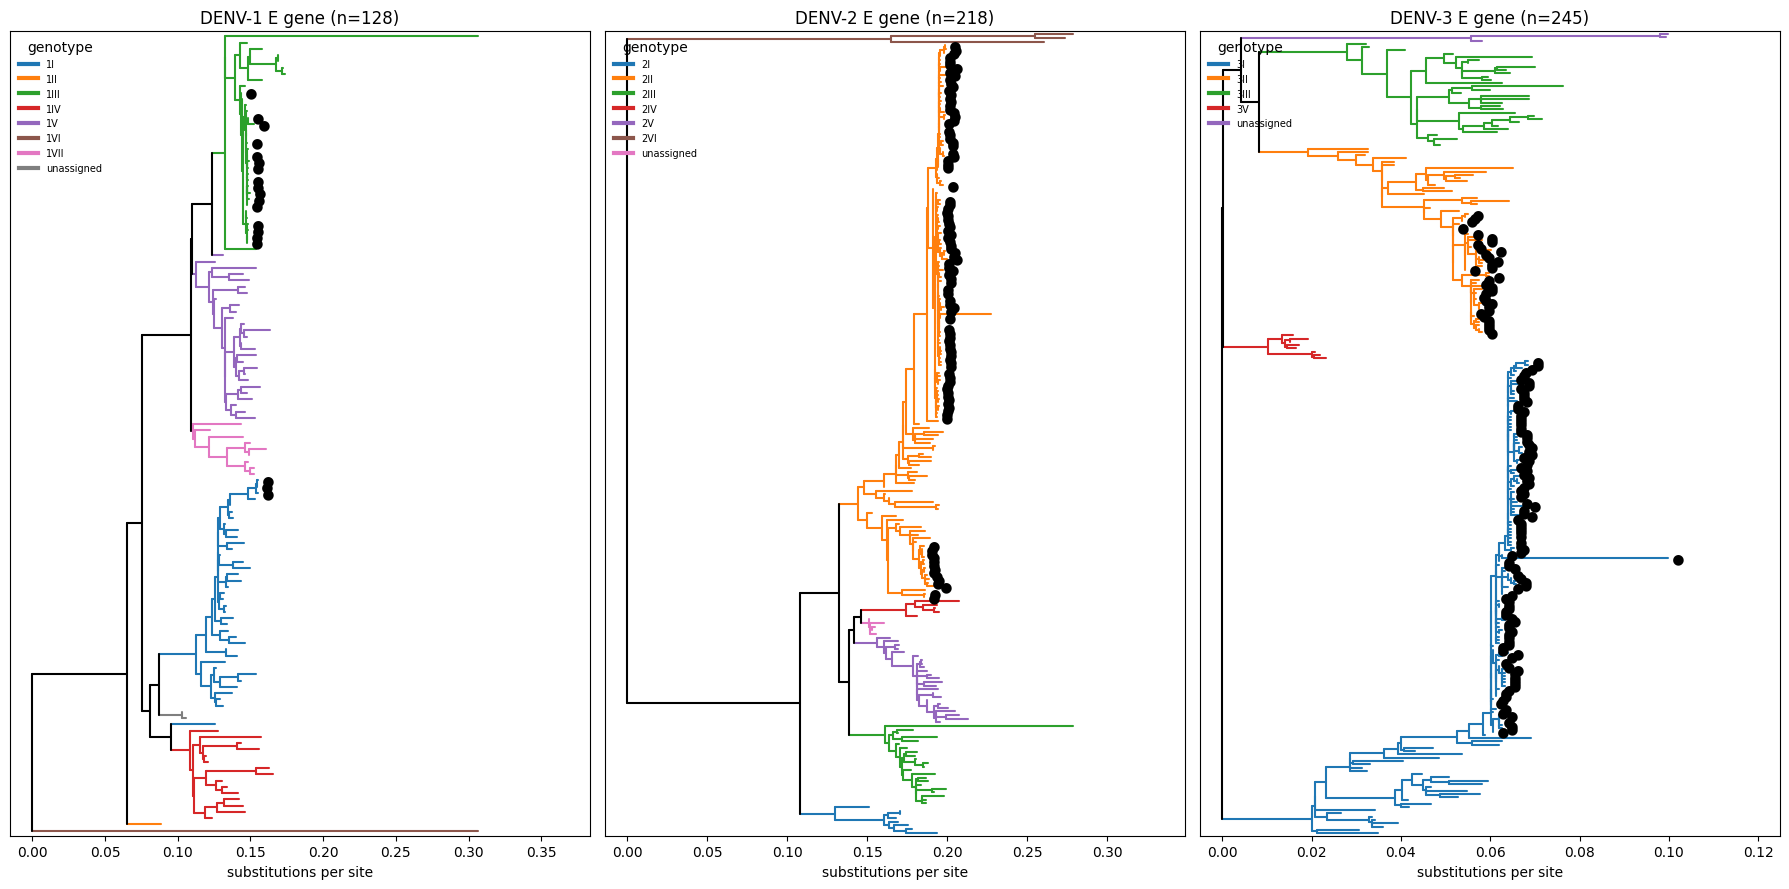

In [ ]:
# Fig 2: E gene trees (branch colour = genotype, black dot = Bangladesh)
from matplotlib.lines import Line2D
from matplotlib.colors import to_hex

fig, axes = plt.subplots(1, 3, figsize=(18, 9))
for ax, s in zip(axes, SEROTYPES):
    info = datasets[f"{s}_E"].set_index("tip")
    genotypes = sorted(info["genotype"].dropna().unique())
    colours = dict(zip(genotypes, [to_hex(c) for c in plt.cm.tab10.colors]))
    tree = Phylo.read(f"{OUT}/trees/{s}_E.treefile", "newick")
    tree.root_at_midpoint()
    for tip in tree.get_terminals():
        tip.color = colours.get(info.loc[tip.name, "genotype"], "gray")
    for node in tree.get_nonterminals(order="postorder"):      # inner branches get a colour when all descendants share it
        kids = {str(ch.color) for ch in node.clades}
        if len(kids) == 1 and node.clades[0].color is not None:
            node.color = node.clades[0].color
    Phylo.draw(tree, axes=ax, label_func=lambda c: "\u25cf" if c.name and c.name.startswith("BD_") else "", do_show=False)
    ax.legend(handles=[Line2D([0], [0], color=c, lw=3, label=g) for g, c in colours.items()], title="genotype", fontsize=7, frameon=False, loc="upper left")
    ax.set_title(f"{s} E gene (n={len(tree.get_terminals())})")
    ax.set_xlabel("substitutions per site")
    ax.set_ylabel("")
    ax.set_yticks([])
plt.tight_layout()
save_fig("Fig2_E_gene_trees")
plt.show()

In [ ]:
# how close are the Bangladeshi E sequences to the nearest foreign sequence?
near = df[df["use_E"] & df["nn_dist"].notna()].copy()
summary = near.groupby("serotype")["nn_dist"].describe()[["count", "min", "50%", "max"]]
summary["identical_to_foreign"] = near[near["nn_dist"] == 0].groupby("serotype").size()
print(summary.fillna(0).to_string())
print(near.groupby(["serotype", "nn_country"]).size().sort_values(ascending=False).groupby("serotype").head(5))
near[["Accession", "serotype", "year", "genotype", "nn_acc", "nn_country", "nn_year", "nn_dist"]].to_csv(f"{OUT}/tables/nearest_foreign_relative.csv", index=False)

          count  min  50%   max  identical_to_foreign
serotype                                             
DENV-1     17.0  1.0  2.0   7.0                   0.0
DENV-2    125.0  0.0  2.0  13.0                  25.0
DENV-3    239.0  0.0  3.0  53.0                  16.0
serotype  nn_country 
DENV-3    USA            108
          China           81
DENV-2    Malaysia        40
          China           39
DENV-3    Myanmar         30
DENV-2    Singapore       27
          Japan           13
DENV-3    Russia          12
DENV-1    Malaysia        12
DENV-3    Philippines      8
DENV-1    Singapore        5
DENV-2    USA              3
dtype: int64


## 9. Temporal signal and dated trees (TreeTime)

Only dated tips of the genotypes found in Bangladesh are used, because mixing distant lineages destroys the clock signal.
Temporal signal is checked with the root-to-tip regression and a date-randomisation test (observed rate compared with rates after shuffling the tip dates).

In [ ]:
def read_clock(folder):
    txt = open(f"{folder}/molecular_clock.txt").read()
    rate = float(re.search(r"--rate:\s*([0-9.eE+-]+)", txt).group(1))
    r2 = float(re.search(r"--r\^2:\s*([0-9.eE+-]+)", txt).group(1))
    return rate, r2

def prepare_dating(name):
    d = datasets[name]
    bd_genotypes = set(d[d["source"] == "Bangladesh"]["genotype"])
    keep = d[d["date_iso"].notna() & d["genotype"].isin(bd_genotypes)]
    tree = Phylo.read(f"{OUT}/trees/{name}.treefile", "newick")
    for tip in [t.name for t in tree.get_terminals() if t.name not in set(keep["tip"])]:
        tree.prune(tip)
    for c in tree.get_nonterminals():      # remove support labels, TreeTime does not need them
        c.name = None
        c.confidence = None
    base = f"{OUT}/work/{name}_dated"
    Phylo.write(tree, base + ".nwk", "newick")
    with open(base + ".fasta", "w") as f:
        for r in SeqIO.parse(f"{OUT}/work/{name}_aln.fasta", "fasta"):
            if r.id in set(keep["tip"]):
                f.write(f">{r.id}\n{str(r.seq)}\n")
    keep[["tip", "date_iso"]].rename(columns={"tip": "name", "date_iso": "date"}).to_csv(base + "_dates.csv", index=False)
    return base, len(keep)

TT = {}
rows = []
for name in datasets:
    base, n = prepare_dating(name)
    if n < 8:
        print(name, "only", n, "dated tips, skipped")
        continue
    common = f"--tree {base}.nwk --aln {base}.fasta --dates {base}_dates.csv --name-column name --date-column date --rng-seed {SEED}"
    out = f"{OUT}/trees/tt_{name}"
    print(name, "TreeTime on", n, "tips ...", flush=True)
    try:
        run(f"treetime {common} --clock-filter 3 --covariation --confidence --reroot least-squares --outdir {out}", log=f"{OUT}/work/{name}_treetime.log")
    except RuntimeError:
        print(name, "TreeTime failed (probably no positive clock signal), see", f"{OUT}/work/{name}_treetime.log")
        continue
    rate, r2 = read_clock(out)

    # date-randomisation test (replicate 0 = real dates, no clock filter; negative rates are allowed because shuffled dates can give them)
    dd = pd.read_csv(base + "_dates.csv")
    reps = {}
    for k in range(N_DRT + 1):
        d2 = dd.copy()
        if k > 0:
            d2["date"] = np.random.RandomState(SEED + k).permutation(d2["date"].values)
        d2.to_csv(f"{OUT}/work/{name}_drt.csv", index=False)
        o = f"{OUT}/work/{name}_drt_{k}"
        try:
            run(f"treetime clock --tree {base}.nwk --aln {base}.fasta --dates {OUT}/work/{name}_drt.csv --name-column name --date-column date "
                f"--reroot least-squares --clock-filter 0 --allow-negative-rate --rng-seed {SEED} --outdir {o}")
            reps[k] = read_clock(o)
        except RuntimeError:
            reps[k] = (np.nan, np.nan)      # no usable root for these dates, counts as "not above the real rate"
    random_rates = [v[0] for k, v in reps.items() if k > 0]
    drt_p = (np.sum(np.array(random_rates) >= reps[0][0]) + 1) / (len(random_rates) + 1)

    outliers = open(f"{out}/outliers.tsv").read().count("\n") - 1 if os.path.exists(f"{out}/outliers.tsv") else 0
    TT[name] = dict(out=out, drt_dir=f"{OUT}/work/{name}_drt_0")
    rows.append(dict(dataset=name, n_tips=n, outliers_removed=max(outliers, 0), rate_clock_filtered=rate, R2_clock_filtered=r2,
                     rate_all_tips=reps[0][0], R2_all_tips=reps[0][1], DRT_p=round(drt_p, 3)))
ts = pd.DataFrame(rows)
ts.to_csv(f"{OUT}/tables/temporal_signal.csv", index=False)
print(ts.to_string(index=False))

DENV-1_E TreeTime on 66 tips ...
DENV-2_E TreeTime on 149 tips ...
DENV-3_E TreeTime on 190 tips ...
DENV-2_genome TreeTime on 125 tips ...
DENV-3_genome TreeTime on 120 tips ...
      dataset  n_tips  outliers_removed  rate_clock_filtered  R2_clock_filtered  rate_all_tips  R2_all_tips  DRT_p
     DENV-1_E      66                 1             0.000213               0.01       0.000197         0.02  0.095
     DENV-2_E     149                 2             0.000737               0.87       0.000731         0.79  0.048
     DENV-3_E     190               159             0.000681               0.86       0.000522         0.57  0.048
DENV-2_genome     125                 6             0.000702               0.95       0.000781         0.91  0.048
DENV-3_genome     120                87             0.000591               0.88       0.000357         0.43  0.048


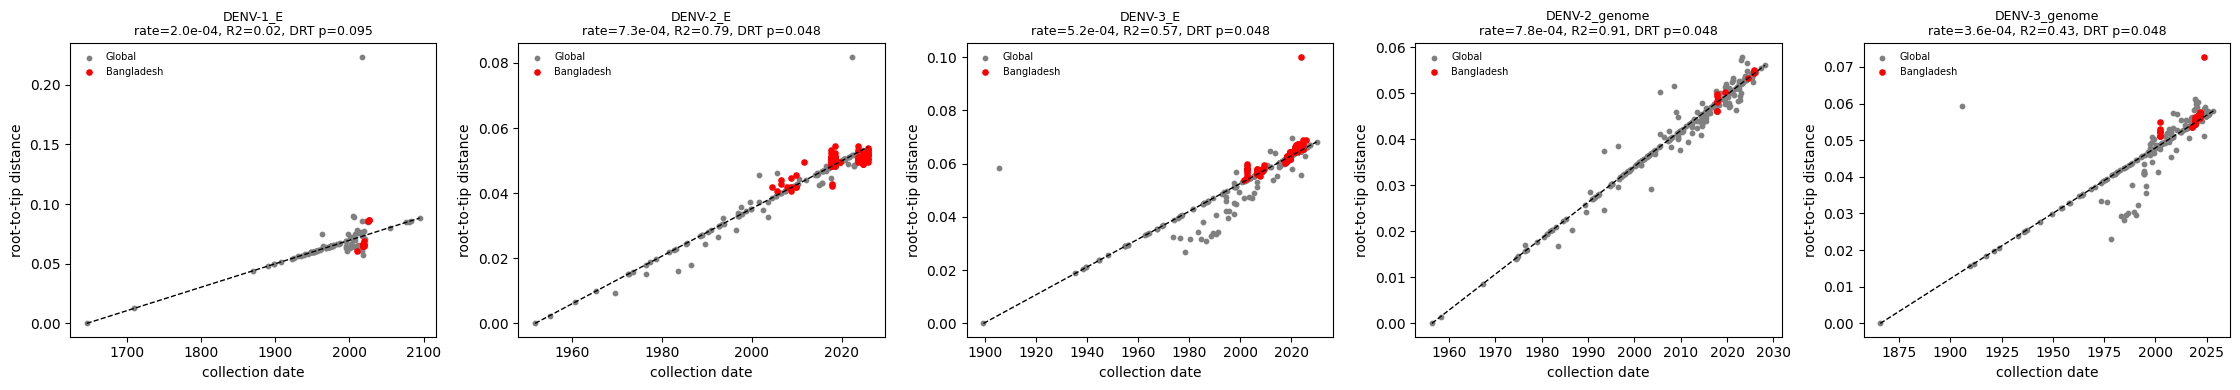

In [ ]:
# Fig 3: root-to-tip regression
names = list(TT)
fig, axes = plt.subplots(1, len(names), figsize=(4.5 * len(names), 4), squeeze=False)
for ax, name in zip(axes[0], names):
    r = pd.read_csv(f"{TT[name]['drt_dir']}/rtt.csv", comment="#", skipinitialspace=True)
    r = r.iloc[:, :3]
    r.columns = ["name", "date", "dist"]
    # ambiguous dates are written as a range (start-end), use the middle of it
    r["date"] = r["date"].astype(str).apply(lambda x: np.mean([float(v) for v in x.split("-") if v.strip()]))
    r["dist"] = r["dist"].astype(float)
    is_bd = r["name"].str.startswith("BD_")
    ax.scatter(r["date"][~is_bd], r["dist"][~is_bd], s=10, color="gray", label="Global")
    ax.scatter(r["date"][is_bd], r["dist"][is_bd], s=14, color="red", label="Bangladesh")
    xs = np.array([r["date"].min(), r["date"].max()])
    ax.plot(xs, np.polyval(np.polyfit(r["date"], r["dist"], 1), xs), "k--", lw=1)
    row = ts[ts["dataset"] == name].iloc[0]
    ax.set_title(f"{name}\nrate={row['rate_all_tips']:.1e}, R2={row['R2_all_tips']:.2f}, DRT p={row['DRT_p']}", fontsize=9)
    ax.set_xlabel("collection date")
    ax.set_ylabel("root-to-tip distance")
    ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
save_fig("Fig3_root_to_tip")
plt.show()

### Bangladesh-only clusters and their dates

A cluster is a group of Bangladeshi sequences that forms its own branch in the dated tree. The cluster MRCA date and the date of its parent node give the likely window of introduction.

In [ ]:
def node_dates(folder):
    lines = [l.rstrip("\n").split("\t") for l in open(f"{folder}/dates.tsv") if l.strip()]
    start = next(i for i, l in enumerate(lines) if l[0].startswith("#node"))
    d = pd.DataFrame(lines[start + 1:], columns=[c.lstrip("#") for c in lines[start]])
    return d.set_index("node")

rows = []
for name in TT:
    tree = Phylo.read(f"{TT[name]['out']}/timetree.nexus", "nexus")
    dates = node_dates(TT[name]["out"])
    ml_tree = Phylo.read(f"{OUT}/trees/{name}.treefile", "newick")

    parent = {}
    for c in tree.find_clades():
        for ch in c.clades:
            parent[ch] = c

    clusters = []
    def walk(c):
        if all(t.name.startswith("BD_") for t in c.get_terminals()):
            clusters.append(c)
        else:
            for ch in c.clades:
                walk(ch)
    walk(tree.root)

    def date_of(c):
        key = None if c is None else (c.name or c.confidence)   # the nexus reader stores node names as confidence
        if key not in dates.index:
            return (np.nan, np.nan, np.nan)
        r = dates.loc[key]
        try:
            return (float(r["numeric date"]), float(r["lower bound"]), float(r["upper bound"]))
        except (ValueError, KeyError):
            return (np.nan, np.nan, np.nan)

    def support_in_ml_tree(tips):
        try:
            anc = ml_tree.common_ancestor(tips)
        except Exception:
            return None
        if {t.name for t in anc.get_terminals()} == set(tips) and anc.name:
            return anc.name
        return None

    singles = sum(1 for c in clusters if c.is_terminal())
    for c in clusters:
        if c.is_terminal():
            continue
        tips = [t.name for t in c.get_terminals()]
        mrca, lo, hi = date_of(c)
        pdate, plo, phi = date_of(parent.get(c))
        years = [int(t.split("_")[-1]) for t in tips if t.split("_")[-1].isdigit()]
        rows.append(dict(dataset=name, n_tips=len(tips), first_year=min(years) if years else None, last_year=max(years) if years else None,
                         MRCA=round(mrca, 1), MRCA_low=round(lo, 1), MRCA_high=round(hi, 1),
                         parent_node=round(pdate, 1), parent_low=round(plo, 1), parent_high=round(phi, 1),
                         ML_support_SHaLRT_UFBoot=support_in_ml_tree(tips)))
    print(name, "| clusters with >=2 sequences:", sum(1 for c in clusters if not c.is_terminal()), "| single introductions-like tips:", singles)

clusters_df = pd.DataFrame(rows).sort_values(["dataset", "n_tips"], ascending=[True, False])
clusters_df.to_csv(f"{OUT}/tables/bangladesh_clusters.csv", index=False)
print(clusters_df.groupby("dataset").head(8).to_string(index=False))

DENV-1_E | clusters with >=2 sequences: 4 | single introductions-like tips: 7
DENV-2_E | clusters with >=2 sequences: 19 | single introductions-like tips: 20
DENV-3_E | clusters with >=2 sequences: 16 | single introductions-like tips: 57
DENV-2_genome | clusters with >=2 sequences: 4 | single introductions-like tips: 1
DENV-3_genome | clusters with >=2 sequences: 7 | single introductions-like tips: 15
      dataset  n_tips  first_year  last_year   MRCA  MRCA_low  MRCA_high  parent_node  parent_low  parent_high ML_support_SHaLRT_UFBoot
     DENV-1_E       4        2017       2018 2015.7    2013.3     2017.2       2013.3      2010.0       2016.1                  84.7/69
     DENV-1_E       3        2025       2025 2020.9    2016.7     2024.0       2007.3      2000.4       2014.0                     None
     DENV-1_E       3        2018       2019 2015.5    2013.3     2017.9       2013.8      2011.7       2016.0                     None
     DENV-1_E       2        2017       2019 2014.5

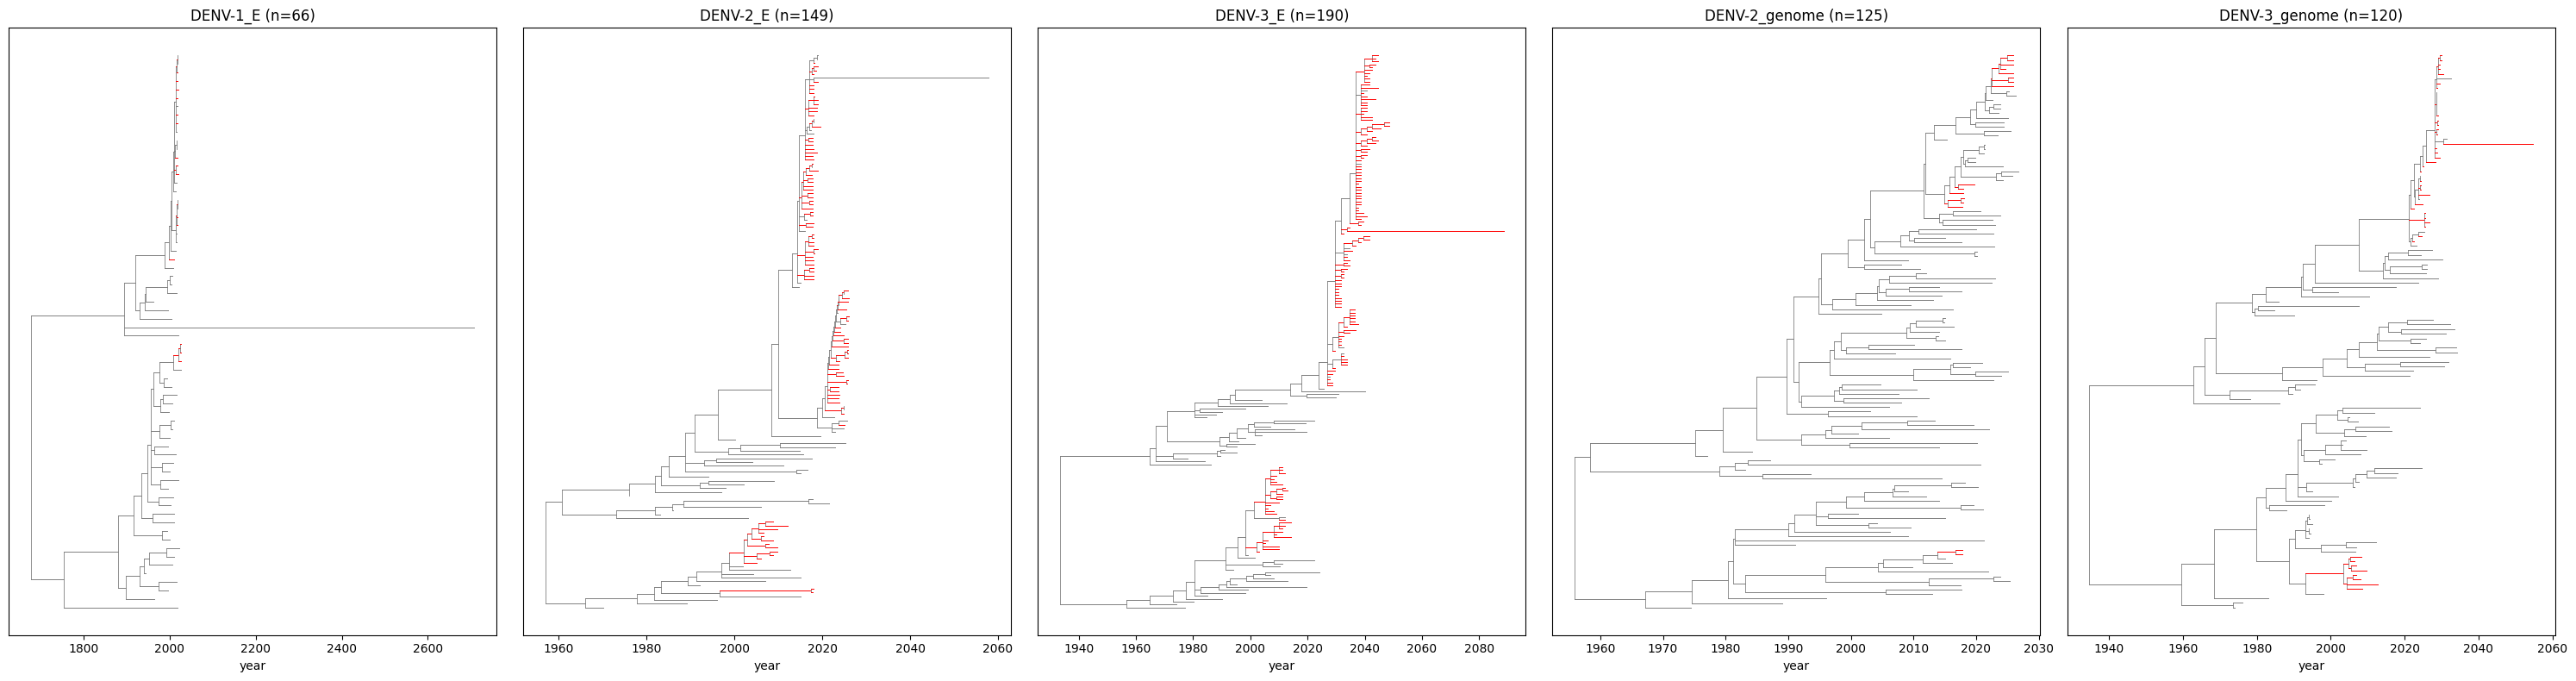

In [ ]:
# Fig 4: time-scaled trees (red = Bangladesh-only branches)
def draw_timetree(name, ax):
    tree = Phylo.read(f"{TT[name]['out']}/timetree.nexus", "nexus")
    dates = node_dates(TT[name]["out"])
    root_date = float(dates.loc[tree.root.name or tree.root.confidence, "numeric date"])
    depth = tree.depths()
    x = {c: root_date + depth[c] for c in tree.find_clades()}
    only_bd = {c: all(t.name.startswith("BD_") for t in c.get_terminals()) for c in tree.find_clades()}
    y = {t: i for i, t in enumerate(tree.get_terminals())}
    for c in tree.get_nonterminals(order="postorder"):
        y[c] = np.mean([y[ch] for ch in c.clades])
    for c in tree.get_nonterminals():
        ax.plot([x[c], x[c]], [y[c.clades[0]], y[c.clades[-1]]], color="gray", lw=0.6)
        for ch in c.clades:
            ax.plot([x[c], x[ch]], [y[ch], y[ch]], color="red" if only_bd[ch] else "gray", lw=0.7)
    ax.set_yticks([])
    ax.set_xlabel("year")
    ax.set_title(f"{name} (n={len(y) - len(tree.get_nonterminals())})")

fig, axes = plt.subplots(1, len(TT), figsize=(6 * len(TT), 8), squeeze=False)
for ax, name in zip(axes[0], TT):
    draw_timetree(name, ax)
plt.tight_layout()
save_fig("Fig4_time_trees")
plt.show()

## 10. Selection analysis on the E gene (HyPhy)

Unique E sequences, in-frame codon alignment, ML tree pruned to the same sequences. Sites are called positive/negative with FEL, SLAC and FUBAR. A site is a consensus site when at least two methods agree.

In [ ]:
STOPS = {"TAA", "TAG", "TGA"}

def to_codons(s):
    out = []
    for i in range(0, len(s) - len(s) % 3, 3):
        c = s[i:i + 3]
        out.append(c if c == "---" else c.replace("-", "N"))
    return out

hy = {}
for s in SEROTYPES:
    name = f"{s}_E"
    seen, kept = set(), {}
    removed_stop = 0
    for r in SeqIO.parse(f"{OUT}/work/{name}_aln.fasta", "fasta"):
        a = str(r.seq).upper()
        if a in seen:
            continue
        seen.add(a)
        codons = to_codons(a)
        if any(c in STOPS for c in codons):
            removed_stop += 1
            continue
        kept[r.id] = "".join(codons)

    aln = f"{OUT}/hyphy/{s}_codon.fasta"
    with open(aln, "w") as f:
        for k, v in kept.items():
            f.write(f">{k}\n{v}\n")

    tree = Phylo.read(f"{OUT}/trees/{name}.treefile", "newick")
    for tip in [t.name for t in tree.get_terminals() if t.name not in kept]:
        tree.prune(tip)
    for c in tree.get_nonterminals():
        c.name = None
        c.confidence = None
    Phylo.write(tree, f"{OUT}/hyphy/{s}.nwk", "newick")
    hy[s] = dict(aln=aln, tree=f"{OUT}/hyphy/{s}.nwk", n=len(kept))
    print(s, "unique sequences:", len(kept), "| removed (stop codon):", removed_stop, "| codons:", len(next(iter(kept.values()))) // 3)

DENV-1 unique sequences: 124 | removed (stop codon): 0 | codons: 495
DENV-2 unique sequences: 210 | removed (stop codon): 0 | codons: 495
DENV-3 unique sequences: 235 | removed (stop codon): 0 | codons: 493


Recombination can give false signals of positive selection, so the E gene alignments are screened with GARD first.

In [ ]:
RUN_GARD = True     # slow (can take hours for big alignments), set to False to skip

if RUN_GARD:
    for s in SEROTYPES:
        out = f"{OUT}/hyphy/{s}_GARD.json"
        if not os.path.exists(out):
            print(s, "GARD running ...", flush=True)
            run(f"hyphy ENV=TOLERATE_NUMERICAL_ERRORS=1 gard --type nucleotide --alignment {hy[s]['aln']} --rv None --mode Faster --output {out}",
                log=f"{OUT}/hyphy/{s}_GARD.log")
        steps = list(json.load(open(out))["improvements"].values())
        n_bp = len(steps) - 1
        print(s, "| breakpoints supported by GARD:", n_bp)
        if n_bp > 0:
            print("   breakpoints:", steps[-1]["breakpoints"], "| delta AICc:", steps[-1]["deltaAICc"])
            print("   -> check the selection results of", s, "with the segments in mind")

In [ ]:
METHODS = ["FEL", "SLAC", "FUBAR"]     # add "MEME" to also test for episodic selection (much slower)

for s in SEROTYPES:
    for m in METHODS:
        out = f"{OUT}/hyphy/{s}_{m}.json"
        if os.path.exists(out):
            continue
        print(s, m, "running ...", flush=True)
        run(f"hyphy {m.lower()} --alignment {hy[s]['aln']} --tree {hy[s]['tree']} --output {out}", log=f"{OUT}/hyphy/{s}_{m}.log")

In [ ]:
P_CUT = 0.1      # FEL, SLAC, MEME
PP_CUT = 0.9     # FUBAR posterior probability

def read_hyphy(path):
    j = json.load(open(path))
    headers = [h[0] for h in j["MLE"]["headers"]]
    rows = j["MLE"]["content"]["0"]
    if isinstance(rows, dict):          # SLAC keeps the site table under by-site
        rows = rows["by-site"]["AVERAGED"]
    d = pd.DataFrame([r[:len(headers)] for r in rows], columns=headers)   # FUBAR rows have extra columns
    d["site"] = np.arange(1, len(d) + 1)
    return d

def find_col(d, pattern):
    return next((c for c in d.columns if re.search(pattern, c, re.I)), None)

def call_sites(method, d):
    pos, neg = set(), set()
    if method == "FEL":
        sig = d[find_col(d, r"^p-value$")] <= P_CUT
        pos = set(d["site"][sig & (d[find_col(d, r"^beta$")] > d[find_col(d, r"^alpha$")])])
        neg = set(d["site"][sig & (d[find_col(d, r"^beta$")] < d[find_col(d, r"^alpha$")])])
    elif method == "MEME":
        pos = set(d["site"][d[find_col(d, r"^p-value$")] <= P_CUT])
    elif method == "SLAC":
        pos = set(d["site"][d[find_col(d, r"P\s*\[dN/dS\s*>\s*1\]")] <= P_CUT])
        neg = set(d["site"][d[find_col(d, r"P\s*\[dN/dS\s*<\s*1\]")] <= P_CUT])
    elif method == "FUBAR":
        pos = set(d["site"][d[find_col(d, r"Prob\[alpha<beta\]")] >= PP_CUT])
        neg = set(d["site"][d[find_col(d, r"Prob\[alpha>beta\]")] >= PP_CUT])
    return pos, neg

# E protein domains (approximate numbering, check against the literature before reporting)
DOMAINS = [("DI", 1, 52), ("DII", 53, 131), ("DI", 132, 193), ("DII", 194, 279), ("DI", 280, 296),
           ("DIII", 297, 394), ("Stem/TM", 395, 495)]
def domain_of(pos):
    return next((n for n, a, b in DOMAINS if a <= pos <= b), "?")

calls, consensus_rows, count_rows = {}, [], []
for s in SEROTYPES:
    calls[s] = {}
    for m in METHODS:
        calls[s][m] = call_sites(m, read_hyphy(f"{OUT}/hyphy/{s}_{m}.json"))
        count_rows.append(dict(serotype=s, method=m, positive_sites=len(calls[s][m][0]), negative_sites=len(calls[s][m][1])))

    aa = {}
    for r in SeqIO.parse(hy[s]["aln"], "fasta"):
        aa[r.id] = str(Seq(str(r.seq)).translate())
    n_codons = len(next(iter(aa.values())))
    for site in range(1, n_codons + 1):
        pos_methods = [m for m in METHODS if site in calls[s][m][0]]
        neg_methods = [m for m in METHODS if site in calls[s][m][1]]
        if len(pos_methods) >= 2 or len(neg_methods) >= 2:
            col = pd.Series([v[site - 1] for v in aa.values() if v[site - 1] not in "X-"])
            consensus_rows.append(dict(serotype=s, site=site, residue=col.mode()[0] if len(col) else "?", domain=domain_of(site),
                                       type="positive" if len(pos_methods) >= 2 else "negative",
                                       methods="+".join(pos_methods if len(pos_methods) >= 2 else neg_methods)))

counts = pd.DataFrame(count_rows)
consensus = pd.DataFrame(consensus_rows)
counts.to_csv(f"{OUT}/tables/selection_counts_by_method.csv", index=False)
consensus.to_csv(f"{OUT}/tables/selection_consensus_sites.csv", index=False)
print(counts.to_string(index=False))
print(consensus[consensus["type"] == "positive"].to_string(index=False))
print(consensus.groupby(["serotype", "type"]).size())

serotype method  positive_sites  negative_sites
  DENV-1    FEL               1             356
  DENV-1   SLAC               0             289
  DENV-1  FUBAR               0             414
  DENV-2    FEL               0             369
  DENV-2   SLAC               0             308
  DENV-2  FUBAR               0             432
  DENV-3    FEL               0             280
  DENV-3   SLAC               0             220
  DENV-3  FUBAR               1             369
Empty DataFrame
Columns: [serotype, site, residue, domain, type, methods]
Index: []
serotype  type    
DENV-1    negative    359
DENV-2    negative    370
DENV-3    negative    286
dtype: int64


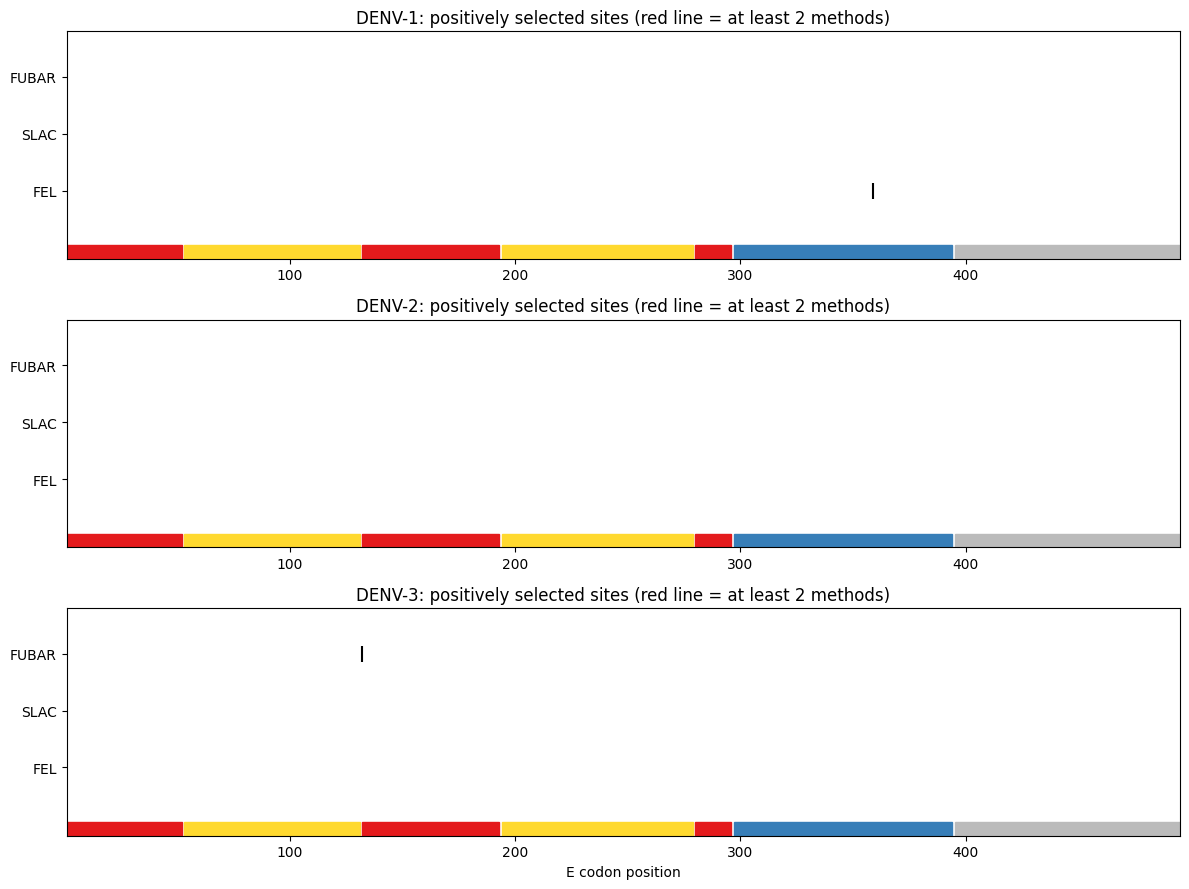

In [ ]:
# Fig 5: sites under selection along the E protein
fig, axes = plt.subplots(len(SEROTYPES), 1, figsize=(12, 3 * len(SEROTYPES)))
for ax, s in zip(axes, SEROTYPES):
    for i, m in enumerate(METHODS):
        pos = sorted(calls[s][m][0])
        ax.scatter(pos, [i + 1] * len(pos), marker="|", s=120, color="black")
    for site in consensus[(consensus["serotype"] == s) & (consensus["type"] == "positive")]["site"]:
        ax.axvline(site, color="crimson", alpha=0.4, lw=1)
    for n, a, b in DOMAINS:
        ax.axvspan(a, b, ymin=0, ymax=0.06, color={"DI": "#e41a1c", "DII": "#ffd92f", "DIII": "#377eb8", "Stem/TM": "#bbbbbb"}[n])
    ax.set_yticks(range(1, len(METHODS) + 1))
    ax.set_yticklabels(METHODS)
    ax.set_xlim(1, 495)
    ax.set_ylim(-0.2, len(METHODS) + 0.8)
    ax.set_title(f"{s}: positively selected sites (red line = at least 2 methods)")
axes[-1].set_xlabel("E codon position")
plt.tight_layout()
save_fig("Fig5_selection")
plt.show()

## 11. Save results

In [ ]:
df.drop(columns=["seq", "E_seq"]).to_csv(f"{OUT}/tables/bangladesh_sequences_annotated.csv", index=False)
for name, d in datasets.items():
    d.drop(columns="seq").to_csv(f"{OUT}/tables/dataset_{name}.csv", index=False)

print(flow.to_string(index=False))
print(tree_info.to_string(index=False))
print(ts.to_string(index=False))

shutil.make_archive("/content/part1_results", "zip", OUT, "tables")
shutil.make_archive("/content/part1_figures", "zip", OUT, "figures")
shutil.make_archive("/content/part1_trees", "zip", OUT, "trees")
try:
    from google.colab import files
    for z in ["part1_results", "part1_figures", "part1_trees"]:
        files.download(f"/content/{z}.zip")
except ImportError:
    pass

                           step   n
      All Bangladeshi sequences 664
 DENV-1/2/3 (sequence-verified) 661
         With E gene >= 1400 bp 437
E gene with few ambiguous bases 430
    Not template or RefSeq-like 411
           With collection year 405
      dataset  n_tips  alignment_length       model  pct_nodes_UFBoot_95  pct_nodes_SHaLRT_80
     DENV-1_E     128              1485 TIM2+F+I+G4                 36.8                 60.0
     DENV-2_E     218              1485   TIM3+F+R4                 31.8                 55.0
     DENV-3_E     245              1479   TIM2+F+G4                 20.3                 40.7
DENV-2_genome     130             10728  GTR+F+I+G4                 75.6                 81.1
DENV-3_genome     127             10712  GTR+F+I+G4                 61.3                 72.6
      dataset  n_tips  outliers_removed  rate_clock_filtered  R2_clock_filtered  rate_all_tips  R2_all_tips  DRT_p
     DENV-1_E      66                 1             0.000213         

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil, os

OUT = "/kaggle/working/part1_outputt"
KAGGLE_OUT = "/kaggle/working"


zips = {
    "part1_results": ("tables",),
    "part1_figures": ("figures",),
    "part1_trees":   ("trees",),
}

for name, sub in zips.items():
    src = os.path.join(OUT, sub[0])
    dst = os.path.join(KAGGLE_OUT, name)
    if os.path.exists(src):
        shutil.make_archive(dst, "zip", src)
        print(f" Created: {dst}.zip  ({os.path.getsize(dst + '.zip')/1024:.1f} KB)")
    else:
        print(f" Missing source folder: {src}")

 Created: /kaggle/working/part1_results.zip  (46.0 KB)
 Created: /kaggle/working/part1_figures.zip  (1135.8 KB)
 Created: /kaggle/working/part1_trees.zip  (16899.4 KB)
